# Verstappen wet-weather analysis

Run top to bottom. Requires `data/store/f1_master.csv` and `data/store/weather.csv` (from `ingest_f1.py`).

**Pre-registered:** the wet/dry thresholds and the primary metric (`tm_delta`) are set in the Setup cell. Set them once, before looking at results. Sections: 1 Audit, 2 Driver battery, 3 Field comparison + sensitivity.

Set `N_PERM`/`N_BOOT` lower (e.g. 300/200) for a quick smoke test; 5000/2000 for final numbers.

## 0. Setup (helpers + thresholds)

In [13]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

STORE = Path("data/store")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

import matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)

START_SEASON = 2018            # FastF1 weather coverage
WET_RAIN_PCT = 20.0            # rain_pct >= this -> "wet"  (rain during >= 20% of the race)
DRY_RAIN_PCT = 2.0             # rain_pct <  this -> "dry". Everything between = "mixed" (excluded from main contrast)
MIN_WET, MIN_DRY = 8, 8        # min usable races per side for field-wide comparison
N_PERM = int(os.environ.get("N_PERM", 5000))
N_BOOT = int(os.environ.get("N_BOOT", 2000))
SEED = 42

# Races where rain_pct disagrees with independent race reports. Every entry needs a source.
# RULE: check ALL "wet" races against a source and fix in BOTH directions, not just the inconvenient ones.
RACE_OVERRIDE = {
    "2018_05": "dry",   # Spain 2018: overnight rain only; race dry (Wikipedia infobox, f1i race report)
    "2019_06": "dry",   # Monaco 2019: rain forecast but race dry (f1-fansite, Planet F1 live text)
}

PRIMARY = "tm_delta"           # pre-registered primary metric (car-controlled)


def load() -> pd.DataFrame:
    df = pd.read_csv(STORE / "f1_master.csv", parse_dates=["date"])
    w = pd.read_csv(STORE / "weather.csv")
    cols = ["race_id", "rain_pct", "is_wet_race"]
    # validate raises if weather.csv has duplicate race_ids (silent row duplication otherwise)
    d = df[df["season"] >= START_SEASON].merge(w[cols], on="race_id", how="inner", validate="m:1")

    d["classified"] = d["status"].str.contains(r"^Finished|^\+\d+ Lap|^Lapped", na=False)  # "Lapped" = finished, a lap+ down
    d["dnf_f"] = (~d["classified"]).astype(float)
    d["win"] = d["is_win"].astype(float)
    d["podium"] = d["is_podium"].astype(float)
    d["grid_eff"] = d["grid"].where(d["grid"] > 0)  # grid 0 = pit-lane start, no meaningful gain
    d["grid_gain"] = (d["grid_eff"] - d["position"]).where(d["classified"])

    # Teammate delta: positive = finished ahead of teammate. Both must be classified.
    c = d.loc[d["classified"], ["race_id", "constructor_id", "driver_id", "position"]]
    tm = c.merge(c, on=["race_id", "constructor_id"], suffixes=("", "_tm"))
    tm = tm[tm["driver_id"] != tm["driver_id_tm"]]
    tmd = tm.groupby(["race_id", "driver_id"], as_index=False)["position_tm"].mean()
    d = d.merge(tmd, on=["race_id", "driver_id"], how="left")
    d["tm_delta"] = (d["position_tm"] - d["position"]).where(d["classified"])
    return d


def add_tier(d: pd.DataFrame, wet_rain_pct: float = WET_RAIN_PCT, mixed_as=None, use_override=True) -> pd.DataFrame:
    """Tier races by rain_pct: wet / dry / mixed. RACE_OVERRIDE (source-checked) wins over rain_pct.
    mixed_as in {None,'wet','dry'} folds mixed into one side."""
    d = d.copy()
    d["tier"] = np.select([d["rain_pct"] >= wet_rain_pct, d["rain_pct"] < DRY_RAIN_PCT], ["wet", "dry"], default="mixed")
    d.loc[d["rain_pct"].isna(), "tier"] = np.nan
    if use_override:
        for rid, t in RACE_OVERRIDE.items():
            d.loc[d["race_id"] == rid, "tier"] = t
    if mixed_as:
        d["tier"] = d["tier"].replace({"mixed": mixed_as})
    return d


# ---------------------------------------------------------------- stats
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centre - half, centre + half


def bh(p):
    """Benjamini-Hochberg adjusted p-values."""
    p = np.asarray(p, float)
    n = len(p)
    o = np.argsort(p)
    adj = p[o] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n)
    out[o] = np.minimum(adj, 1)
    return out


def _adj_diff(y, w, groups):
    """Season-adjusted wet-minus-dry difference: within each season (that has both), wet mean - dry mean,
    weighted by number of wet races. Removes 'wet races happened to fall in his weak/strong seasons'."""
    num = den = 0.0
    for g in groups:
        wg, yg = w[g], y[g]
        nw = wg.sum()
        if 0 < nw < len(g):
            num += nw * (yg[wg].mean() - yg[~wg].mean())
            den += nw
    return num / den if den else np.nan


def season_adjusted_diff(sub: pd.DataFrame, metric: str, n_perm=N_PERM, n_boot=N_BOOT, seed=SEED) -> dict:
    """sub = one driver's rows with tier in {wet, dry}.
    p_perm : two-sided, wet/dry labels shuffled WITHIN season (null = no wet effect, car-year held fixed).
    CI     : bootstrap resampling races within each season x tier cell."""
    s = sub.dropna(subset=[metric])
    y = s[metric].to_numpy(float)
    w = (s["tier"] == "wet").to_numpy()
    se = s["season"].to_numpy()
    out = dict(n_wet=int(w.sum()), n_dry=int((~w).sum()),
               wet_mean=y[w].mean() if w.any() else np.nan,
               dry_mean=y[~w].mean() if (~w).any() else np.nan,
               adj_diff=np.nan, ci_lo=np.nan, ci_hi=np.nan, p_perm=np.nan, n_wet_used=0)
    seasons = np.unique(se)
    groups = [np.where(se == x)[0] for x in seasons]
    obs = _adj_diff(y, w, groups)
    if np.isnan(obs):
        return out
    out["adj_diff"] = obs
    out["n_wet_used"] = int(sum(w[g].sum() for g in groups if 0 < w[g].sum() < len(g)))

    rng = np.random.default_rng(seed)
    ge = 0
    for _ in range(n_perm):
        wp = w.copy()
        for g in groups:
            wp[g] = rng.permutation(w[g])
        if abs(_adj_diff(y, wp, groups)) >= abs(obs) - 1e-12:
            ge += 1
    out["p_perm"] = (ge + 1) / (n_perm + 1)

    cells = [np.where((se == x) & (w == t))[0] for x in seasons for t in (True, False)]
    cells = [c for c in cells if len(c)]
    boots = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(c, len(c), replace=True) for c in cells])
        yb, wb, sb = y[idx], w[idx], se[idx]
        gb = [np.where(sb == x)[0] for x in np.unique(sb)]
        boots.append(_adj_diff(yb, wb, gb))
    out["ci_lo"], out["ci_hi"] = np.nanpercentile(np.array(boots, float), [2.5, 97.5])
    return out


## 1. Audit: data integrity and wet definition

Check that the printed 'wet' list matches races you know were wet **before** moving on. Fix thresholds in Setup if not.

In [14]:

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)

d = add_tier(load())
print(f"Rows {len(d):,} | seasons {d.season.min()}-{d.season.max()} | races {d.race_id.nunique()}")

print("\n== Integrity ==")
dup = d.duplicated(["race_id", "driver_id"]).sum()
print("duplicate (race_id, driver_id) rows:", dup)
print("races with <18 or >22 drivers:\n", d.groupby("race_id").size().loc[lambda s: (s < 18) | (s > 22)])
print("missing weather:", d["tier"].isna().sum(), "rows")

print("\n== Weather columns ==")
print(d.drop_duplicates("race_id")[["rain_pct"]].describe().round(1))

races = (d.drop_duplicates("race_id")
         [["race_id", "season", "round", "race_name", "circuit_id", "rain_pct", "is_wet_race", "tier"]]
         .sort_values(["season", "round"]))
races.to_csv(OUT / "race_tiers.csv", index=False)

print("\n== Old flag (is_wet_race) vs new tier ==")
print(pd.crosstab(races["is_wet_race"], races["tier"], margins=True))
print("\nRaces your old flag called wet but are NOT 'wet' under the new tiering:")
print(races[(races["is_wet_race"]) & (races["tier"] != "wet")].to_string(index=False))
print("\nTier counts by season:")
print(pd.crosstab(races["season"], races["tier"]))
print("\nEYEBALL 'wet' list against what you remember (Spa 2021, Brazil 2024, etc.):")
print(races[races["tier"] == "wet"][["season", "race_name", "rain_pct"]].to_string(index=False))

print("\nOverrides applied (each needs a source):", RACE_OVERRIDE)
print("\nCHECK EVERY ROW ABOVE against a race report / FIA race weather report. Fix RACE_OVERRIDE in Setup, both directions.")
print("\n== The identical-47 check: wet rows per driver (all vs classified) ==")
for n in ["Max Verstappen", "Lewis Hamilton"]:
    s = d[(d.full_name == n) & (d.tier == "wet")]
    print(f"{n}: wet rows={len(s)}, classified={int(s.classified.sum())}, DNF={int((~s.classified).sum())}")
print("\nStatus values among non-classified rows (is any 'DNF' actually a non-incident, e.g. DSQ/DNS?):")
print(d.loc[~d.classified, "status"].value_counts().head(20))


Rows 3,898 | seasons 2018-2026 | races 193

== Integrity ==
duplicate (race_id, driver_id) rows: 0
races with <18 or >22 drivers:
 Series([], dtype: int64)
missing weather: 0 rows

== Weather columns ==
       rain_pct
count     193.0
mean        5.3
std        16.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max        98.0

== Old flag (is_wet_race) vs new tier ==
tier         dry  mixed  wet  All
is_wet_race                      
False        145      0    0  145
True          13     19   16   48
All          158     19   16  193

Races your old flag called wet but are NOT 'wet' under the new tiering:
race_id  season  round             race_name    circuit_id  rain_pct  is_wet_race  tier
2018_01    2018      1 Australian Grand Prix   albert_park       4.5         True mixed
2018_03    2018      3    Chinese Grand Prix      shanghai       1.8         True   dry
2018_05    2018      5    Spanish Grand Prix     catalunya      79.0         True   dry
2018_06    2018 

## 2. Driver battery: wet minus dry

`tm_delta` / `grid_gain`: positive = better in wet. `dnf_f`: positive = more DNFs in wet. Mixed races excluded.

In [15]:

pd.set_option("display.width", 200, "display.max_columns", 30)
DRIVERS = ["Max Verstappen", "Lewis Hamilton", "Fernando Alonso", "Lando Norris", "Charles Leclerc"]
METRICS = ["tm_delta", "grid_gain", "win", "podium", "dnf_f"]

d = add_tier(load())
print("Tier counts per driver (all rows):")
print(pd.crosstab(d[d.full_name.isin(DRIVERS)].full_name, d.tier))
d = d[d.tier.isin(["wet", "dry"])]

rows = []
for drv in DRIVERS:
    sub = d[d.full_name == drv]
    if sub.empty:
        print(f"WARNING: no rows for {drv}")
        continue
    for m in METRICS:
        r = season_adjusted_diff(sub, m)
        r.update(driver=drv, metric=m)
        rows.append(r)
res = pd.DataFrame(rows)[["driver", "metric", "n_wet", "n_dry", "n_wet_used", "wet_mean", "dry_mean",
                          "adj_diff", "ci_lo", "ci_hi", "p_perm"]]
res.to_csv(OUT / "driver_battery.csv", index=False)
print("\n== Wet minus dry (season-adjusted). tm_delta/grid_gain: + = better in wet. dnf_f: + = MORE DNFs in wet ==")
print(res.round(3).to_string(index=False))

print("\n== Raw win rate with Wilson 95% CI ==")
for drv in DRIVERS:
    for t in ("wet", "dry"):
        s = d[(d.full_name == drv) & (d.tier == t)]
        k, n = int(s.win.sum()), len(s)
        lo, hi = wilson(k, n)
        print(f"{drv:18s} {t}: {k}/{n} = {k / max(n, 1):.0%}  [{lo:.0%}, {hi:.0%}]")

cols = ["season", "round", "race_name", "rain_pct", "grid", "position", "status", "tm_delta", "grid_gain"]
log = d[(d.full_name == "Max Verstappen") & (d.tier == "wet")].sort_values(["season", "round"])[cols]
log.to_csv(OUT / "verstappen_wet_races.csv", index=False)
print("\n== Verstappen wet-race log (use these in the article) ==")
print(log.to_string(index=False))


Tier counts per driver (all rows):
tier             dry  mixed  wet
full_name                       
Charles Leclerc  158     19   16
Fernando Alonso  123     17   15
Lando Norris     142     16   14
Lewis Hamilton   157     19   16
Max Verstappen   158     19   16

== Wet minus dry (season-adjusted). tm_delta/grid_gain: + = better in wet. dnf_f: + = MORE DNFs in wet ==
         driver    metric  n_wet  n_dry  n_wet_used  wet_mean  dry_mean  adj_diff  ci_lo  ci_hi  p_perm
 Max Verstappen  tm_delta     10    119          10     7.200     4.000     3.595  1.933  5.216   0.002
 Max Verstappen grid_gain     16    137          16     1.688     1.358     0.424 -1.420  2.365   0.681
 Max Verstappen       win     16    158          16     0.562     0.361     0.143 -0.056  0.320   0.237
 Max Verstappen    podium     16    158          16     0.750     0.665     0.063 -0.091  0.205   0.717
 Max Verstappen     dnf_f     16    158          16     0.000     0.133    -0.123 -0.188 -0.066   0.220
 Le

## 3. Field comparison and sensitivity

Teammate deltas are zero-sum within a pair, so cross-check with grid gain, win and DNF rows from section 2.

== Field-wide wet-minus-dry teammate delta (13 drivers with >= 8 wet & 8 dry races) ==
 rank          driver  n_wet  n_dry  adj_diff  ci_lo  ci_hi  p_perm  p_bh
    1  Max Verstappen     10    119     3.595  1.908  5.109   0.002 0.026
    2  Lewis Hamilton     12    134     1.447  0.397  2.650   0.109 0.285
    3 Valtteri Bottas      8    109     0.708 -0.631  2.040   0.567 0.899
    4    Pierre Gasly     12    111     0.522 -1.633  2.440   0.702 0.900
    5    Carlos Sainz      8    108     0.278 -1.860  2.351   0.843 0.913
    6    Lando Norris     12    114     0.021 -2.188  2.182   0.990 0.990
    7 Fernando Alonso     11     78    -0.421 -1.821  1.215   0.762 0.900
    8    Esteban Ocon     14     99    -0.570 -1.854  0.792   0.622 0.899
    9  George Russell     11    112    -0.598 -2.524  1.523   0.556 0.899
   10    Yuki Tsunoda     11     66    -1.031 -3.615  1.600   0.497 0.899
   11 Charles Leclerc     10    122    -2.089 -3.528 -0.651   0.037 0.162
   12    Lance Stroll    

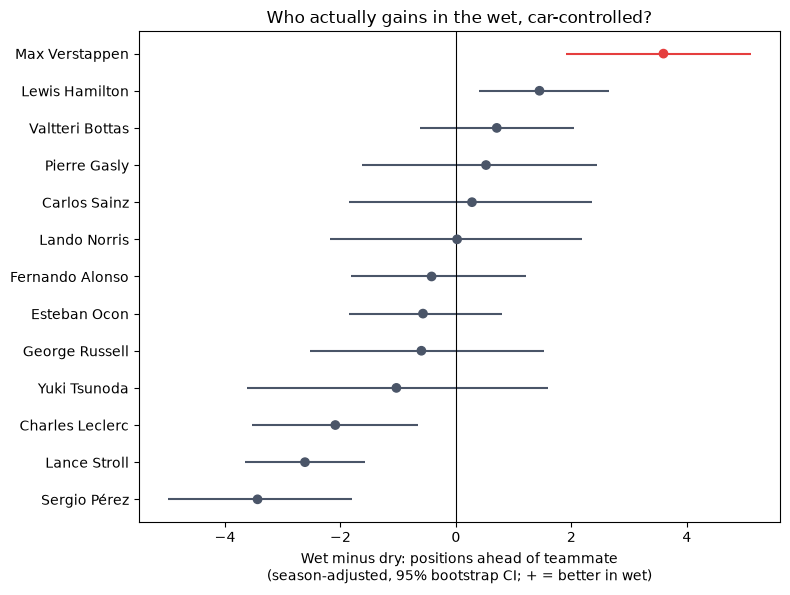


== Verstappen: sensitivity to wet definition (report the whole range, not the best row) ==
  metric  wet_rain_pct mixed_as  overrides  n_wet  n_dry  adj_diff  ci_lo  ci_hi  p_perm
tm_delta            10 excluded       True     15    119     2.423  0.510  4.176   0.018
     win            10 excluded       True     22    158     0.028 -0.150  0.201   0.794
   dnf_f            10 excluded       True     22    158    -0.080 -0.167  0.000   0.269
tm_delta            10      wet       True     27    119     0.634 -0.840  2.223   0.424
     win            10      wet       True     35    158    -0.026 -0.165  0.113   0.740
   dnf_f            10      wet       True     35    158    -0.109 -0.185 -0.042   0.076
tm_delta            10      dry       True     15    131     2.592  0.620  4.632   0.005
     win            10      dry       True     22    171     0.038 -0.135  0.201   0.795
   dnf_f            10      dry       True     22    171    -0.068 -0.155  0.009   0.298
tm_delta          

In [16]:

pd.set_option("display.width", 200, "display.max_columns", 30)
TARGET = "Max Verstappen"
base = load()

# ---- (a) field-wide, primary metric
d = add_tier(base)
d = d[d.tier.isin(["wet", "dry"])]
rows = []
for drv, sub in d.groupby("full_name"):
    s = sub.dropna(subset=[PRIMARY])
    if (s.tier == "wet").sum() < MIN_WET or (s.tier == "dry").sum() < MIN_DRY:
        continue
    r = season_adjusted_diff(sub, PRIMARY, n_perm=min(N_PERM, 2000), n_boot=min(N_BOOT, 1000))
    r["driver"] = drv
    rows.append(r)
if not rows:
    nr = d.drop_duplicates("race_id")
    print("No driver has enough wet AND dry races with a valid teammate delta.")
    print("Race tiers:", nr["tier"].value_counts().to_dict())
    print("rain_pct describe:\n", nr["rain_pct"].describe().round(1))
    print("Most wet rows for any driver:", d[d.tier == "wet"].groupby("full_name").size().max())
    raise RuntimeError("Fix wet thresholds (WET_RAIN_PCT) or lower MIN_WET/MIN_DRY in Setup.")
res = pd.DataFrame(rows).dropna(subset=["adj_diff"])
res["p_bh"] = bh(res["p_perm"].to_numpy())
res = res.sort_values("adj_diff", ascending=False).reset_index(drop=True)
res["rank"] = res.index + 1
res.to_csv(OUT / "field_tm_delta.csv", index=False)
print(f"== Field-wide wet-minus-dry teammate delta ({len(res)} drivers with >= {MIN_WET} wet & {MIN_DRY} dry races) ==")
print(res[["rank", "driver", "n_wet", "n_dry", "adj_diff", "ci_lo", "ci_hi", "p_perm", "p_bh"]].round(3).to_string(index=False))
print("NOTE: teammate deltas are zero-sum within a pair (VER +x  <=>  teammate -x). A big gap can be the teammate collapsing in the wet. Cross-check with grid_gain / win / dnf in 02.")
print(f"\nDrivers with raw p<0.05: {(res.p_perm < .05).sum()} of {len(res)} (chance alone gives ~{0.05 * len(res):.1f})")
print(f"Drivers with BH-adjusted p<0.05: {(res.p_bh < .05).sum()}")
if TARGET in set(res.driver):
    r = res[res.driver == TARGET].iloc[0]
    print(f"{TARGET}: rank {int(r['rank'])}/{len(res)}, diff {r.adj_diff:+.2f} [{r.ci_lo:+.2f}, {r.ci_hi:+.2f}], p={r.p_perm:.3f}, BH p={r.p_bh:.3f}")

p = res.sort_values("adj_diff")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(p) + 1.5))
y = np.arange(len(p))
col = ["#e53e3e" if n == TARGET else "#4a5568" for n in p.driver]
ax.hlines(y, p.ci_lo, p.ci_hi, colors=col)
ax.scatter(p.adj_diff, y, c=col, zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(p.driver)
ax.set_xlabel("Wet minus dry: positions ahead of teammate\n(season-adjusted, 95% bootstrap CI; + = better in wet)")
ax.set_title("Who actually gains in the wet, car-controlled?")
plt.tight_layout()
plt.savefig(OUT / "field_forest.png", dpi=150)
plt.show()

# ---- (b) sensitivity of the Verstappen result to the wet definition
sens = []
sub_all = base[base.full_name == TARGET]
configs = [(wl, ma, True) for wl in (10, 20, 30, 40) for ma in (None, "wet", "dry")] + [(wl, None, False) for wl in (10, 20, 30, 40)]
for wl, mixed_as, ov in configs:
    t = add_tier(sub_all, wet_rain_pct=wl, mixed_as=mixed_as, use_override=ov)
    t = t[t.tier.isin(["wet", "dry"])]
    for m in (PRIMARY, "win", "dnf_f"):
        r = season_adjusted_diff(t, m, n_perm=min(N_PERM, 2000), n_boot=min(N_BOOT, 1000))
        r.update(wet_rain_pct=wl, mixed_as=mixed_as or "excluded", overrides=ov, metric=m)
        sens.append(r)
sens = pd.DataFrame(sens)[["metric", "wet_rain_pct", "mixed_as", "overrides", "n_wet", "n_dry", "adj_diff", "ci_lo", "ci_hi", "p_perm"]]
sens.to_csv(OUT / "verstappen_sensitivity.csv", index=False)
print("\n== Verstappen: sensitivity to wet definition (report the whole range, not the best row) ==")
print(sens.round(3).to_string(index=False))
